# Structured Products Pricing

This first Notebook aims to visualize what was first done with regard to the Black-Scholes model, the Greeks as well as the Monte Carlo simulation.
We will therefore see how all of the above behaves - with regard to several parameters - and compare to one another.

 ### Section 1 : Imports

In [2]:
import sys
sys.path.append("C:/Users/ledou/Documents/Structured-Products-Pricing/src")

import numpy as np
import matplotlib.pyplot as plt
import black_scholes as bs
import monte_carlo as mc

### Section 2 : Price and Payoff

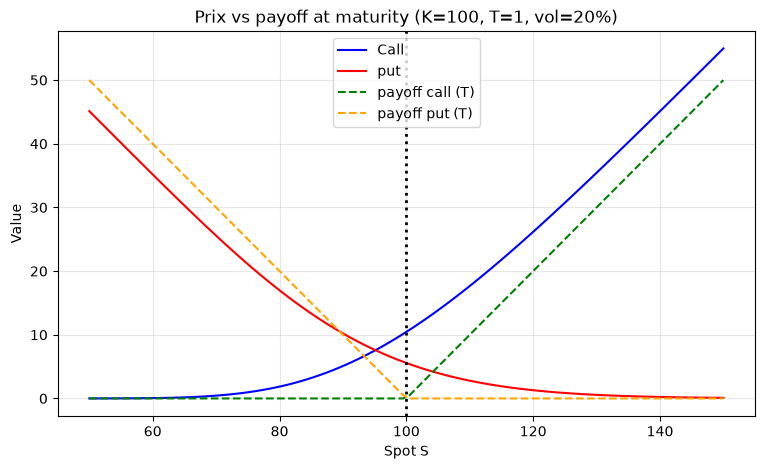

In [3]:
S = np.linspace(50, 150, 100)
K = 100
call = bs.bs_call(S, K=K, T=1, r=0.05, sigma=0.2, q=0.0)
put = bs.bs_put(S, K=K, T=1, r=0.05, sigma=0.2, q=0.0)

payoff_call = np.maximum(S-K, 0)
payoff_put = np.maximum(K-S, 0)

fig, ax = plt.subplots(figsize=(9,5))

ax.plot(S, call, label = 'Call', color = 'blue')
ax.plot(S, put, label = 'put', color = 'red')

ax.plot(S, payoff_call, "--", color = 'green', label = "payoff call (T)")
ax.plot(S, payoff_put, "--", color = 'orange', label = "payoff put (T)")

ax.axvline(K, color="black", linewidth=2, linestyle=":")
ax.set_xlabel("Spot S")
ax.set_ylabel("Value")
ax.set_title("Prix vs payoff at maturity (K=100, T=1, vol=20%)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

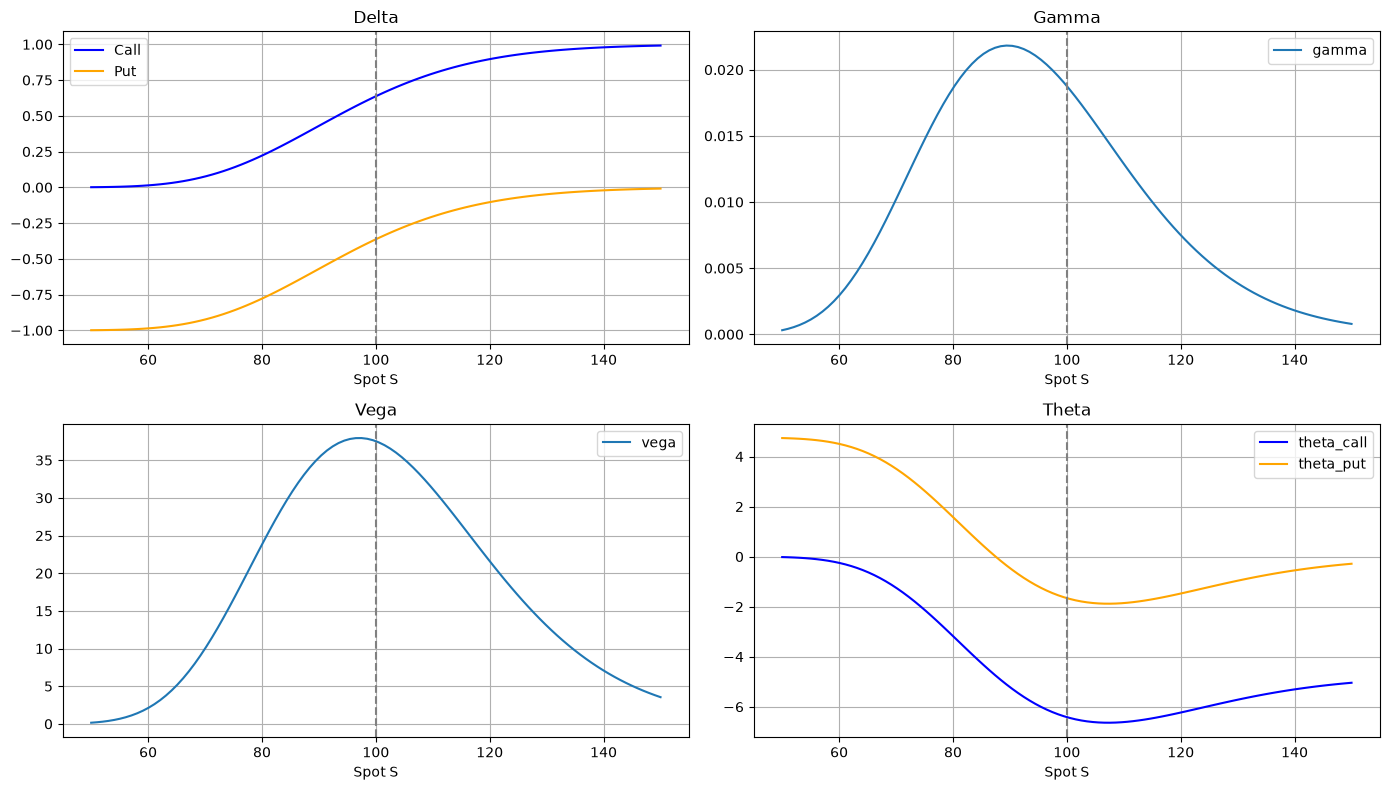

In [4]:
params = dict(S=np.linspace(50, 150, 100), K = 100, T=1, r=0.05, sigma=0.2, q=0.0)
call = bs.bs_call(**params)
put = bs.bs_put(**params)

delta_call = bs.bs_delta_call(**params)
delta_put = bs.bs_delta_put(**params)
gamma = bs.bs_gamma(**params)
vega = bs.bs_vega(**params)
theta_call = bs.bs_theta_call(**params)
theta_put = bs.bs_theta_put(**params)

fig, axes = plt.subplots(2,2, figsize=(14,8))

# delta
ax = axes[0, 0]
ax.plot(S, delta_call, label="Call", color='blue')
ax.plot(S, delta_put, label="Put", color='orange')
ax.axvline(100, linestyle="--", color="grey")
ax.set_title("Delta")
ax.set_xlabel("Spot S")
ax.legend()
ax.grid(True)

# gamma
ax = axes[0, 1]
ax.plot(S, gamma, label="gamma")
ax.axvline(100, linestyle="--", color="grey")
ax.set_title("Gamma")
ax.set_xlabel("Spot S")
ax.legend()
ax.grid(True)

# vega
ax = axes[1, 0]
ax.plot(S, vega, label="vega")
ax.axvline(100, linestyle="--", color="grey")
ax.set_title("Vega")
ax.set_xlabel("Spot S")
ax.legend()
ax.grid(True)

# theta
ax = axes[1, 1]
ax.plot(S, theta_call, label="theta_call", color='blue')
ax.plot(S, theta_put, label="theta_put", color='orange')
ax.axvline(100, linestyle="--", color="grey")
ax.set_title("Theta")
ax.set_xlabel("Spot S")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

Le gamma, le vega et le theta sont maximaux (en valeur absolue) près de la monnaie, mais pas exactement en S = K : la dérive r et l’asymétrie de la loi log-normale (correction −σ²/2) décalent les pics vers la gauche, et l’écart s’annule quand r et σ tendent vers 0. Avec ces paramètres, le gamma culmine vers S ≈ 89,6 (d₁ = −σ√T) et le vega vers S ≈ 97 (d₁ = +σ√T).

# Section 4 : Gamma and maturity

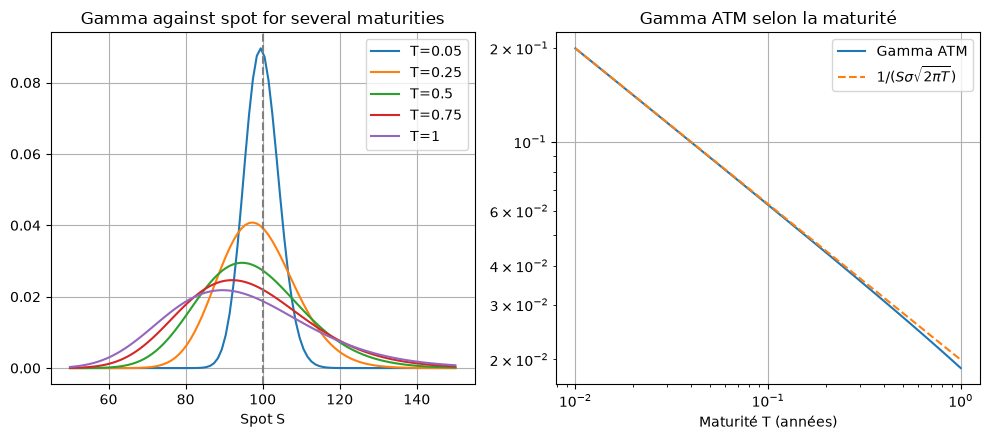

In [5]:
maturities = (0.05, 0.25, 0.5, 0.75, 1)

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))

# gauche
ax = axes[0]
for t in maturities :
    gamma = bs.bs_gamma(S=np.linspace(50, 150, 100), K=100, T=t, r=0.05, sigma= 0.2, q=0.0)
    ax.plot(S, gamma, label=f"T={t}")
ax.axvline(100, linestyle="--", color="grey")
ax.set_title("Gamma against spot for several maturities")
ax.set_xlabel("Spot S")
ax.legend()
ax.grid(True)

#droite
T_grid = np.logspace(-2, 0, 100)
gamma_atm = bs.bs_gamma(S=100, K=100, T=T_grid, r=0.05, sigma=0.2, q=0.0)
gamma_approx = 1 / (100 * 0.2 * np.sqrt(2 * np.pi * T_grid))

ax = axes[1]
ax.loglog(T_grid, gamma_atm, label="Gamma ATM")
ax.loglog(T_grid, gamma_approx, linestyle="--", label=r"$1/(S\sigma\sqrt{2\pi T})$")
ax.set_title("Gamma ATM selon la maturité")
ax.set_xlabel("Maturité T (années)")
ax.legend()
ax.grid(True)


plt.tight_layout()
plt.show()


Quand l’échéance approche, le gamma d’une option à la monnaie diverge comme 1/√T (pente −1/2 en échelle log-log) : un petit mouvement du spot modifie fortement le delta, donc la couverture est de plus en plus instable et coûteuse à rebalancer. Le pic se rapproche aussi de S = K, car la dérive et la correction −σ²/2 deviennent négligeables.

# Section 5

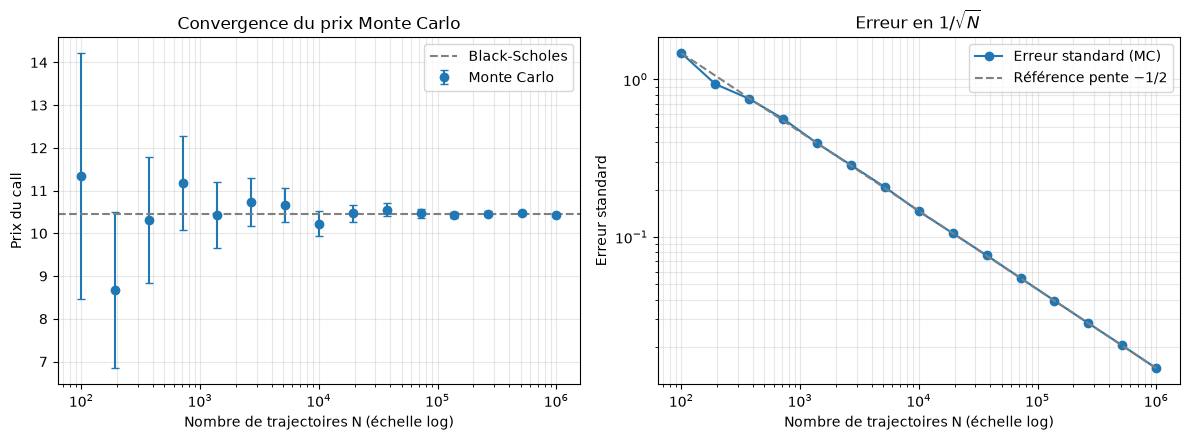

In [13]:
mc_params = dict(S=100, K=100, T=1.0, r=0.05, sigma=0.2, q=0.0)
bs_price = bs.bs_call(**mc_params)

Ns = np.logspace(2, 6, 15).astype(int)
prices, ses = [], []


for i, n in enumerate(Ns):
    price, se, _ = mc.mc_european(**mc_params, option_type="call", n_paths=n, seed=i)
    prices.append(price)
    ses.append(se)

prices, ses = np.array(prices), np.array(ses)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Graphique 1 : convergence du prix ---
ax = axes[0]
ax.errorbar(Ns, prices, yerr=1.96*ses, fmt="o", capsize=3, label="Monte Carlo")
ax.axhline(bs_price, linestyle="--", color="grey", label="Black-Scholes")
ax.set_xscale("log")                       # sinon les petits N sont écrasés à gauche
ax.set_xlabel("Nombre de trajectoires N (échelle log)")
ax.set_ylabel("Prix du call")
ax.set_title("Convergence du prix Monte Carlo")
ax.legend()
ax.grid(True, which="both", alpha=0.3)

# --- Graphique 2 : vitesse de convergence ---
ax = axes[1]
ax.loglog(Ns, ses, "o-", label="Erreur standard (MC)")
ax.loglog(Ns, ses[-1]*np.sqrt(Ns[-1]/Ns), "--", color="grey", label=r"Référence pente $-1/2$")
ax.set_xlabel("Nombre de trajectoires N (échelle log)")
ax.set_ylabel("Erreur standard")
ax.set_title(r"Erreur en $1/\sqrt{N}$")
ax.legend()
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()